# EmPath: imagery-based GeoAI and walking-route demonstration

**This notebook runs a real pretrained neural network**, Restor/ETH Zurich TCD SegFormer-B0, using PyTorch and Transformers. It does not train from scratch or use an AI API. It predicts tree cover from USDA NAIP aerial imagery, polygonizes the predictions, measures canopy near walking segments, and compares route costs.

**Coverage:** one small imagery tile in each of 75023, 75024, 75025 and 75074, not complete coverage of those ZIPs. Existing production graph and canopy attributes remain unchanged. Vegetation/grass, parking lots, buildings, and sidewalk extraction are not inferred by this tree model.

**Important:** the model was trained on 10 cm imagery; these NAIP tiles are 60 cm. Local transfer accuracy is unknown. Tree cover near a sidewalk is a proxy for potential protection, not measured afternoon shade or thermal stress.

Use **Python (EmPath)** and Run All. First run downloads imagery and model weights; subsequent runs reuse saved predictions. Dependencies are in `requirements-imagery-geoai.txt`.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'scripts').exists(): ROOT=ROOT.parent
assert (ROOT/'scripts').exists(), 'Open this notebook from EmPath.'
sys.path.insert(0,str(ROOT/'scripts'))
from IPython.display import display, Image, Markdown
import pandas as pd, json

## 1. Acquire georeferenced imagery
Public-domain NAIP accessed through Microsoft Planetary Computer. The manifest records source URLs, acquisition dates, resolution and valid-image coverage. No Google Maps screenshot or CARTO imagery is used for inference.

In [2]:
from imagery_geoai_demo import acquire_demo_imagery, segment_all, vectorize_and_measure
records=acquire_demo_imagery()
display(pd.DataFrame([{k:r[k] for k in ['zip','year','resolution_m','valid_fraction','scope']} for r in records]))

,zip,year,resolution_m,valid_fraction,scope
0,75023,2022,0.6,1.0,Small demonstration tile; NOT complete ZIP cov...
1,75024,2022,0.6,1.0,Small demonstration tile; NOT complete ZIP cov...
2,75025,2022,0.6,1.0,Small demonstration tile; NOT complete ZIP cov...
3,75074,2022,0.6,1.0,Small demonstration tile; NOT complete ZIP cov...


## 2. Apply the pretrained GeoAI model
Inference runs in overlapping 512-pixel windows. Averaged tree probabilities are thresholded at 0.5, an explicit model operating choice. Raster NoData is retained. A saved model manifest records the checkpoint revision and checksum. Delete the saved mask/probability files only if you deliberately want to rerun inference.

In [3]:
segment_all(records)
print('Saved real model predictions for',len(records),'demonstration tiles.')
display(json.loads((ROOT/'output/vegetation_geoai/model_provenance.json').read_text()))

Saved real model predictions for 4 demonstration tiles.


/Users/nalinikantheti/Documents/ChatGPT/EmPath/.venv/lib/python3.12/site-packages/transformers/utils/deprecation.py:165: UserWarning: The following named arguments are not valid for `SegformerImageProcessor.__init__` and were ignored: '_valid_processor_keys'
  return func(*args, **kwargs)


{'model_id': 'restor/tcd-segformer-mit-b0',
 'revision': '904e2fb0696abb4bae63f43344bd99ec1959d092',
 'weights_sha256': '5bd5b2dbb6a9ae6d7e993cef3c1b717209a861605cc6a15fd75529e536e49e01',
 'classes': {'0': '__background__', '1': 'tree'},
 'device': 'cpu',
 'torch': '2.2.2',
 'trained_resolution_m': 0.1,
 'inference_resolution_m': 0.6,
 'domain_shift': 'NAIP is coarser than the 10 cm model training imagery; predictions require local validation. No artificial upsampling claimed as extra detail.',
 'model_card': 'https://huggingface.co/restor/tcd-segformer-mit-b0',
 'license_note': 'Research demonstration. Review model card: SegFormer research terms and CC BY/NC training sources before deployment.'}

## 3. Create vectors and walking-edge attributes
The predicted binary mask becomes tree polygons. A 5 m buffer around each OSM walking segment defines its canopy corridor. Partial imagery coverage is recorded explicitly; partial block observations must not be interpreted as whole-block means.

In [4]:
trees,edges,block_parts=vectorize_and_measure(records)
display(edges[['u','v','key','demo_zip','ai_tree_cover_01','imagery_corridor_coverage_01','complete_corridor']].head())
display(block_parts[['GEOID20','ai_tree_percent_observed_part','imagery_block_coverage_01']].head())

,u,v,key,demo_zip,ai_tree_cover_01,imagery_corridor_coverage_01,complete_corridor
0,150052849,5246526854,0,75023,0.007013,0.994973,True
1,150052849,150065287,0,75023,0.000000,0.996466,True
2,150052849,150065298,0,75023,0.000000,1.000000,True
3,150052855,5246526862,0,75023,0.065546,1.000000,True
4,150052855,5246526854,0,75023,0.012346,1.000000,True


,GEOID20,ai_tree_percent_observed_part,imagery_block_coverage_01
0,480850316283010,0.196464,0.005772
1,480850316341002,13.985214,0.041861
2,480850316432018,1.594331,0.005929
3,480850316341006,14.668652,1.000000
4,480850316131001,14.927863,0.646875


## 4. Compare routes

Distance baseline: add segment lengths.

AI-informed **scenario**: `length × [1 + beta × (1 − predicted nearby tree fraction)]`.

`beta` is the previously fitted Singapore sun/distance coefficient. Substituting canopy proximity for sun exposure is an unvalidated approximation. This does **not** mean the model learned Plano comfort, traffic danger, or temperature.

Only edges whose full 5 m corridor lies within valid imagery are used. Endpoints are demonstration graph nodes, not verified homes/service entrances. One deterministic source is screened against reachable destinations 200–1,000 m away; the displayed destination maximizes the observed proxy-cost difference. All candidates are saved to disclose this exploratory selection. Routes may remain identical. This is a demonstration, not an unbiased evaluation.

**Tree-adjacency priority:** an additional, separate route maximizes length-weighted mean predicted tree cover among the first 30 loopless candidate paths no longer than 1.5× the shortest route. This bounded search is not a claim of the globally most shaded route. Default route colors show tree adjacency, not routing method; dashed/dotted/solid outlines distinguish methods.

In [5]:
from geoai_route_demo import route_demo
comparison=route_demo()
display(comparison)

,zip,route,origin_node,destination_node,distance_m,mean_tree_adjacency_01,candidate_limit,detour_limit_ratio,ai_canopy_gap_proxy_m,cost_equivalent_m,longest_low_canopy_edge_run_m,route_changed,access_verified
0,75023,Shortest distance,5000939117,5000924516,864.882171,0.006275,30,1.5,859.454742,1028.702916,864.882171,False,False
1,75023,AI canopy proxy,5000939117,5000924516,868.596206,0.057836,30,1.5,818.360185,1024.583914,375.605874,True,False
2,75023,Tree-adjacency priority,5000939117,5000924516,885.522480,0.070806,30,1.5,822.821856,1042.360627,375.605874,True,False
3,75024,Shortest distance,7272249381,3653446646,989.022908,0.001241,30,1.5,987.795278,1177.306655,989.022908,False,False
4,75024,AI canopy proxy,7272249381,3653446646,989.022908,0.001241,30,1.5,987.795278,1177.306655,989.022908,False,False
5,75024,Tree-adjacency priority,7272249381,3653446646,992.520309,0.003537,30,1.5,989.010192,1181.035631,992.520309,True,False
6,75025,Shortest distance,7229627409,7890707382,963.953683,0.078591,30,1.5,888.195638,1133.252733,674.916314,False,False
7,75025,AI canopy proxy,7229627409,7890707382,965.295245,0.105290,30,1.5,863.659713,1129.917500,674.916314,True,False
8,75025,Tree-adjacency priority,7229627409,7890707382,965.295245,0.105290,30,1.5,863.659713,1129.917500,674.916314,True,False
9,75074,Shortest distance,5797694583,150172848,685.806861,0.079410,30,1.5,631.346843,806.147939,343.371006,False,False


## 5. Export interactive and document-ready maps

{'inference_completed': True,
 'full_zip_coverage': False,
 'demo_tiles': 4,
 'tree_polygon_count': 811,
 'attributed_directed_edges': 3684,
 'edges_with_full_corridor_coverage': 3128,
 'validation': 'Review template and 16 imagery-only patches provided. Independent manual labels not yet supplied; no local accuracy claimed.',
 'production_graph_modified': False,
 'next_step': 'Review predictions and route accessibility before replacing production features or expanding imagery coverage.'}

### ZIP 75023

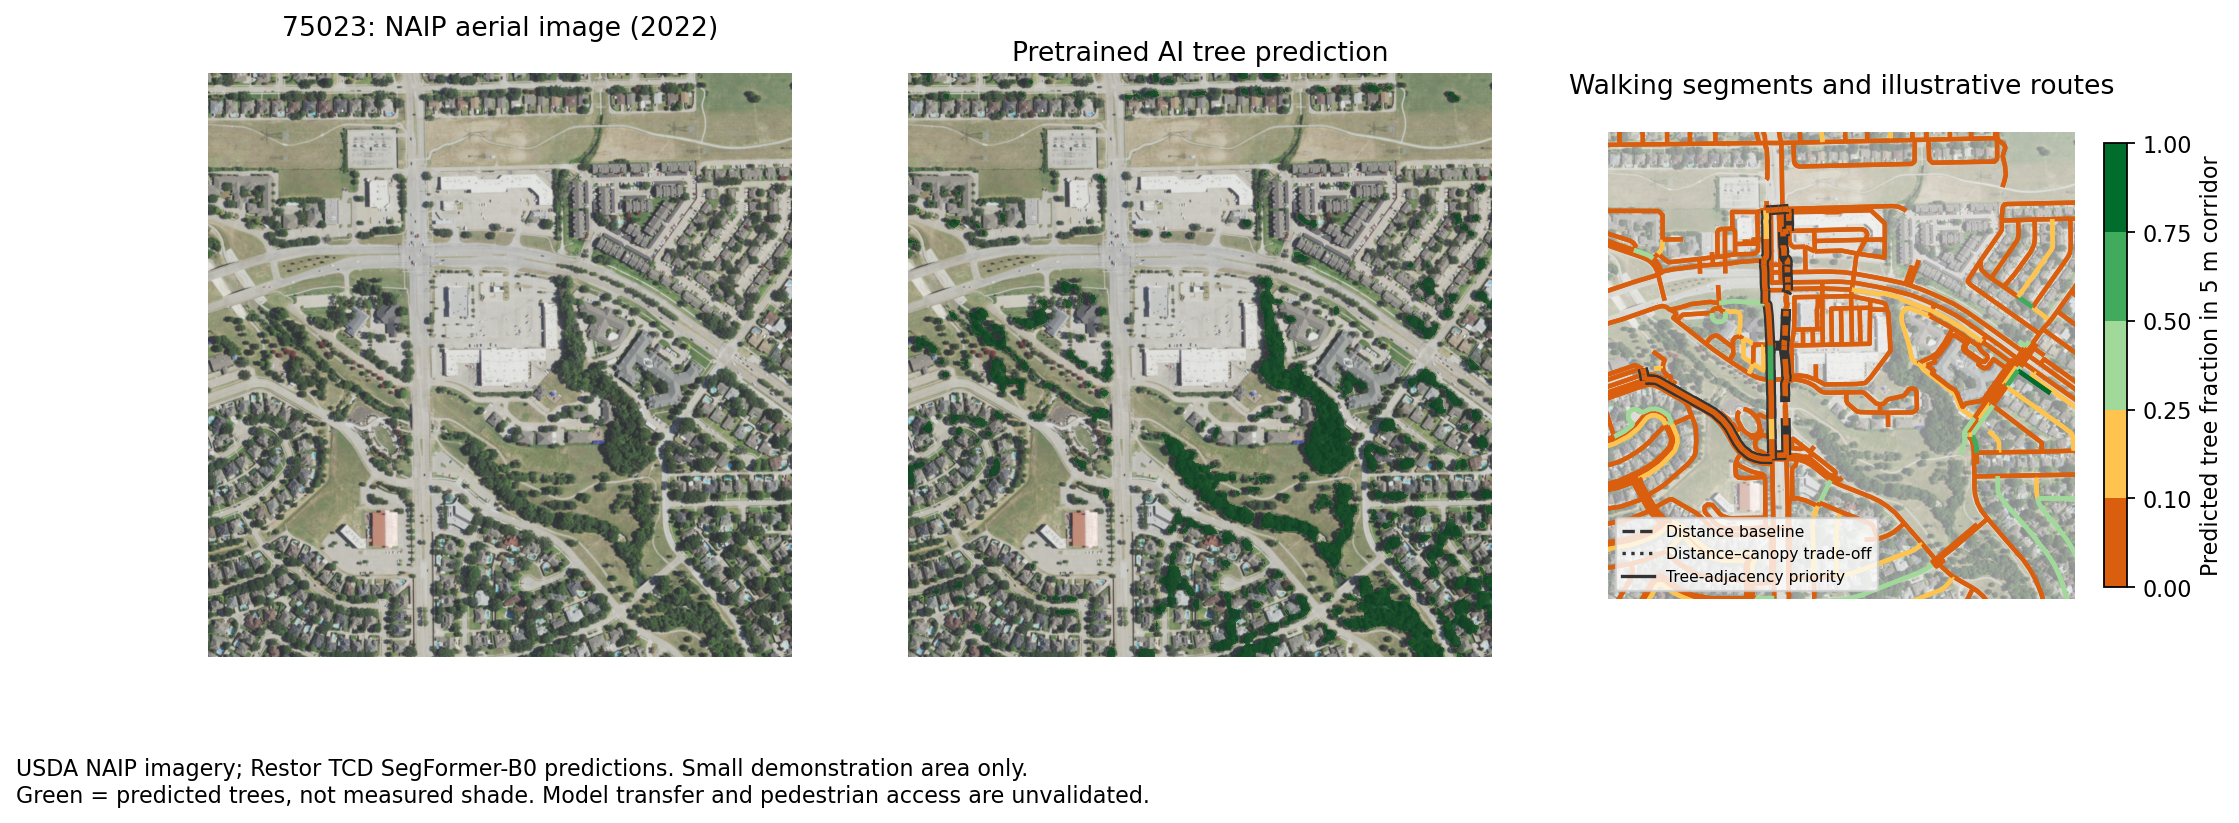

### ZIP 75024

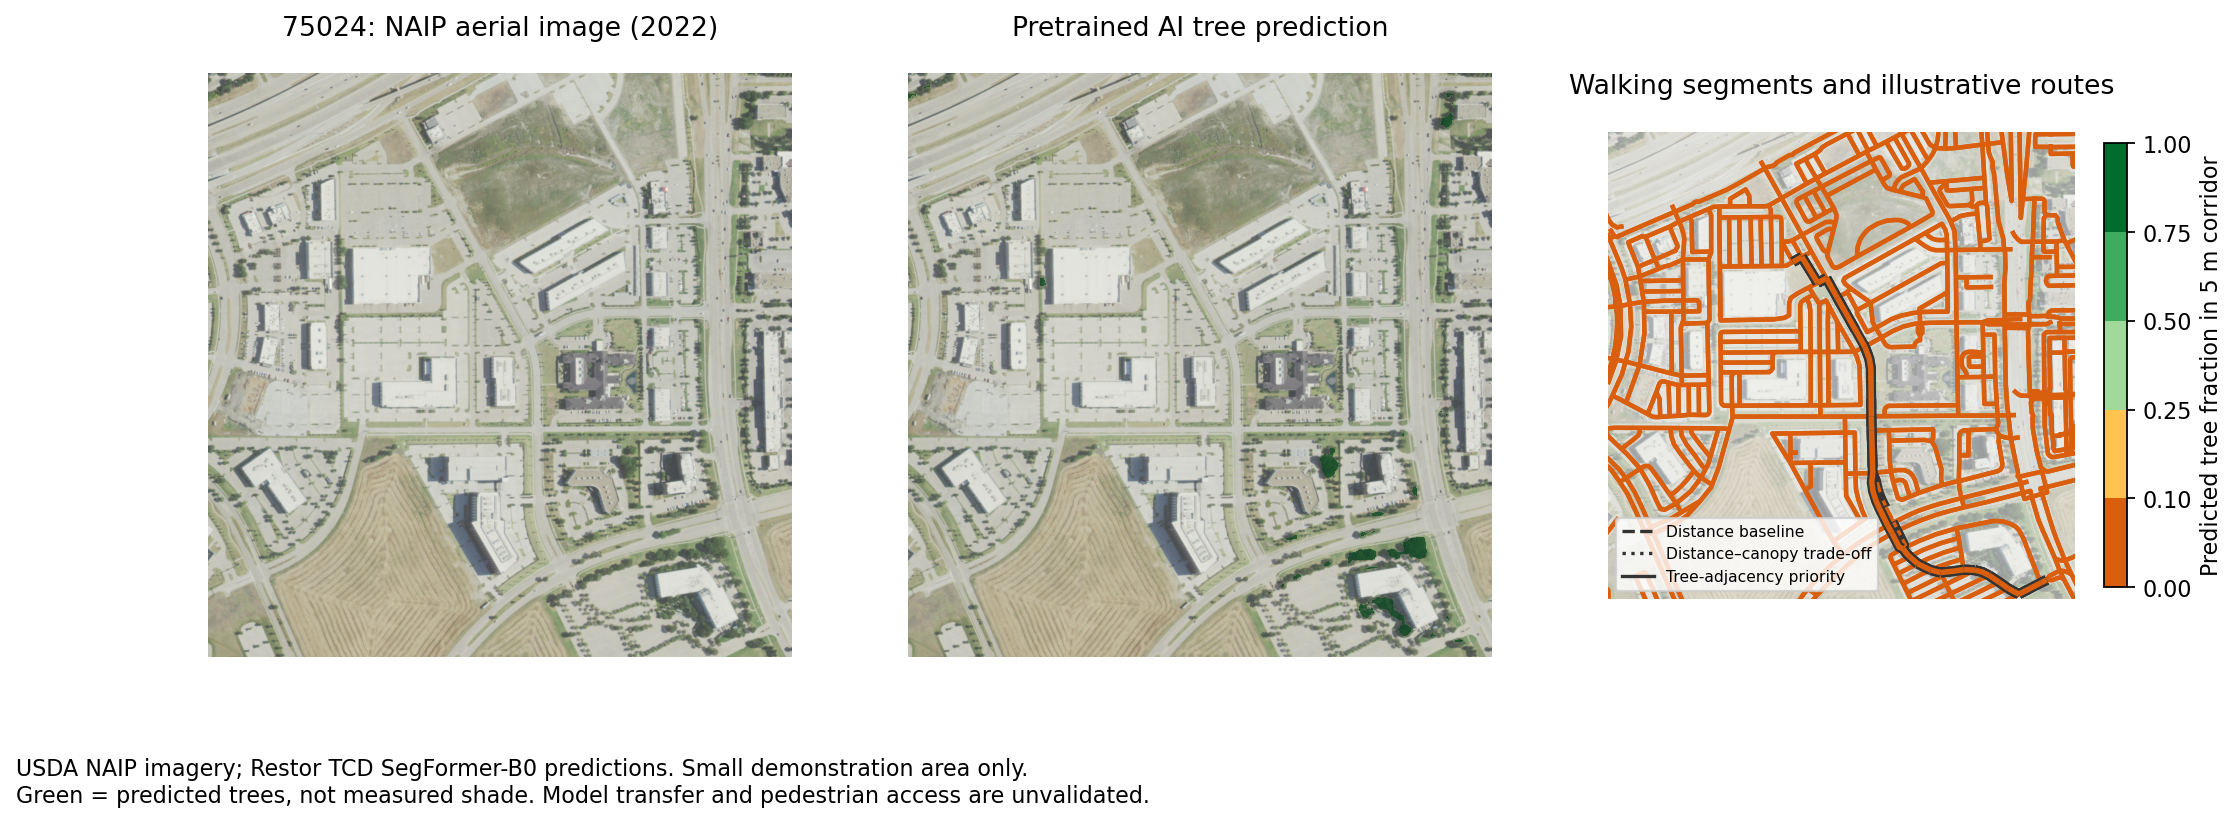

### ZIP 75025

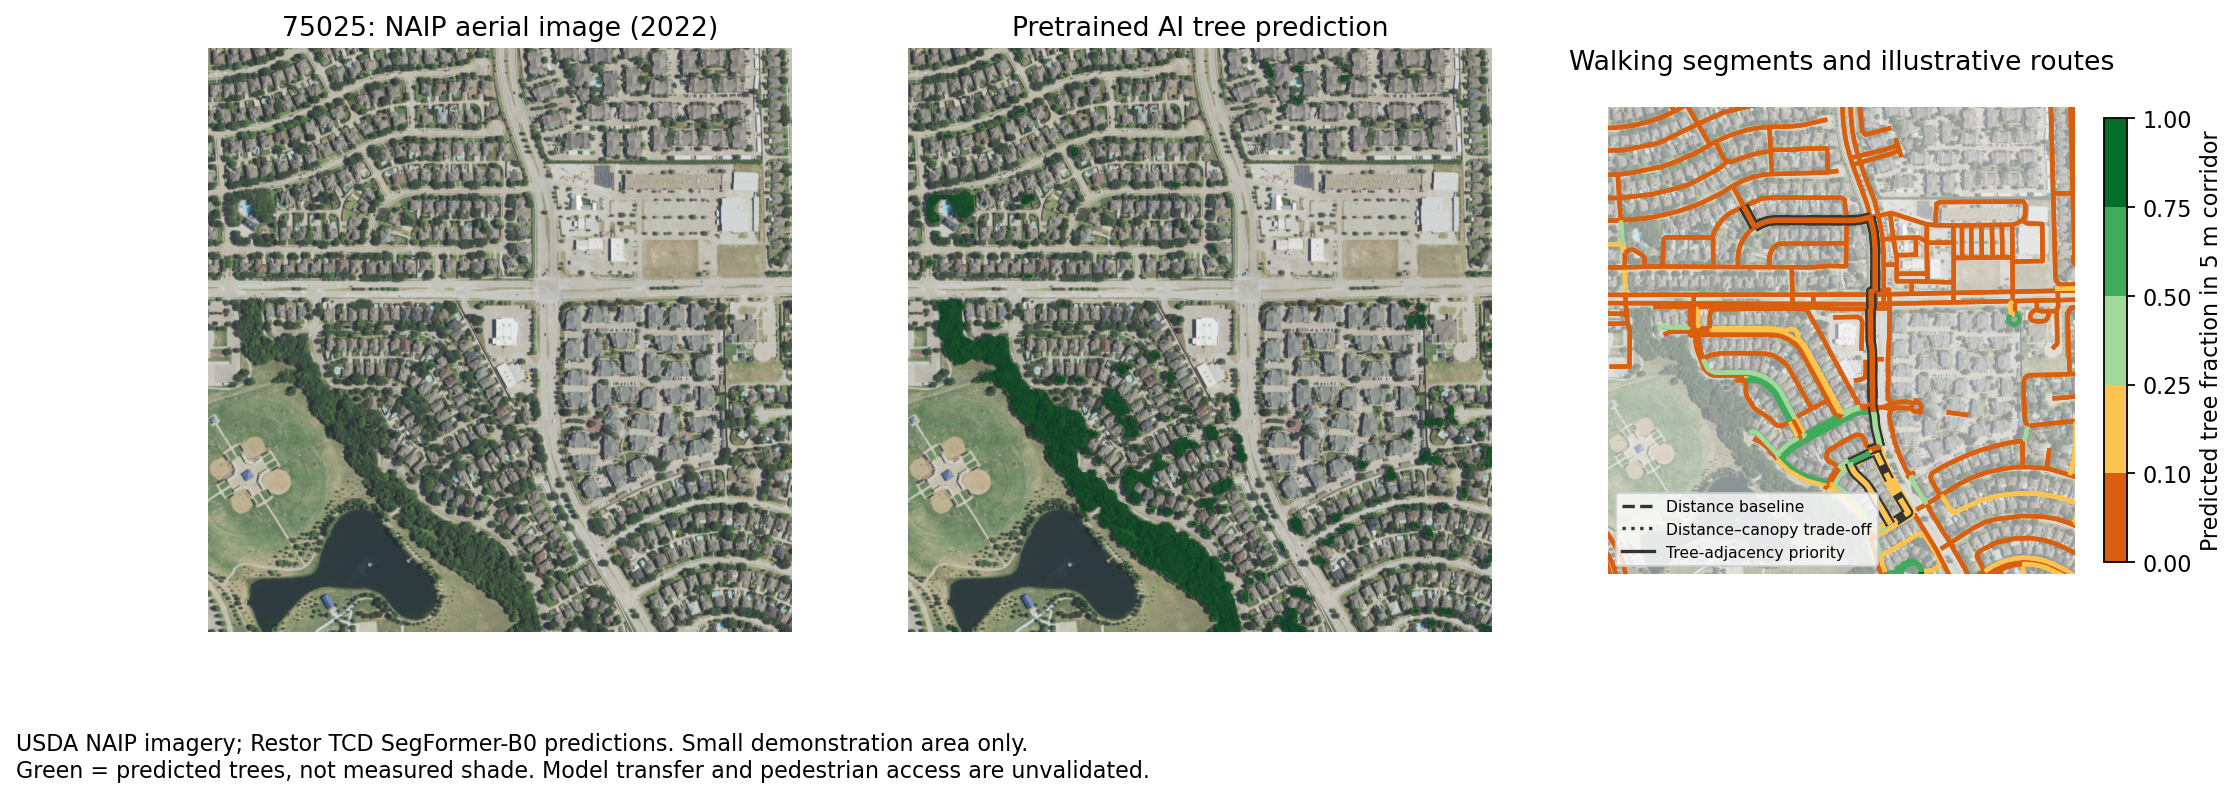

### ZIP 75074

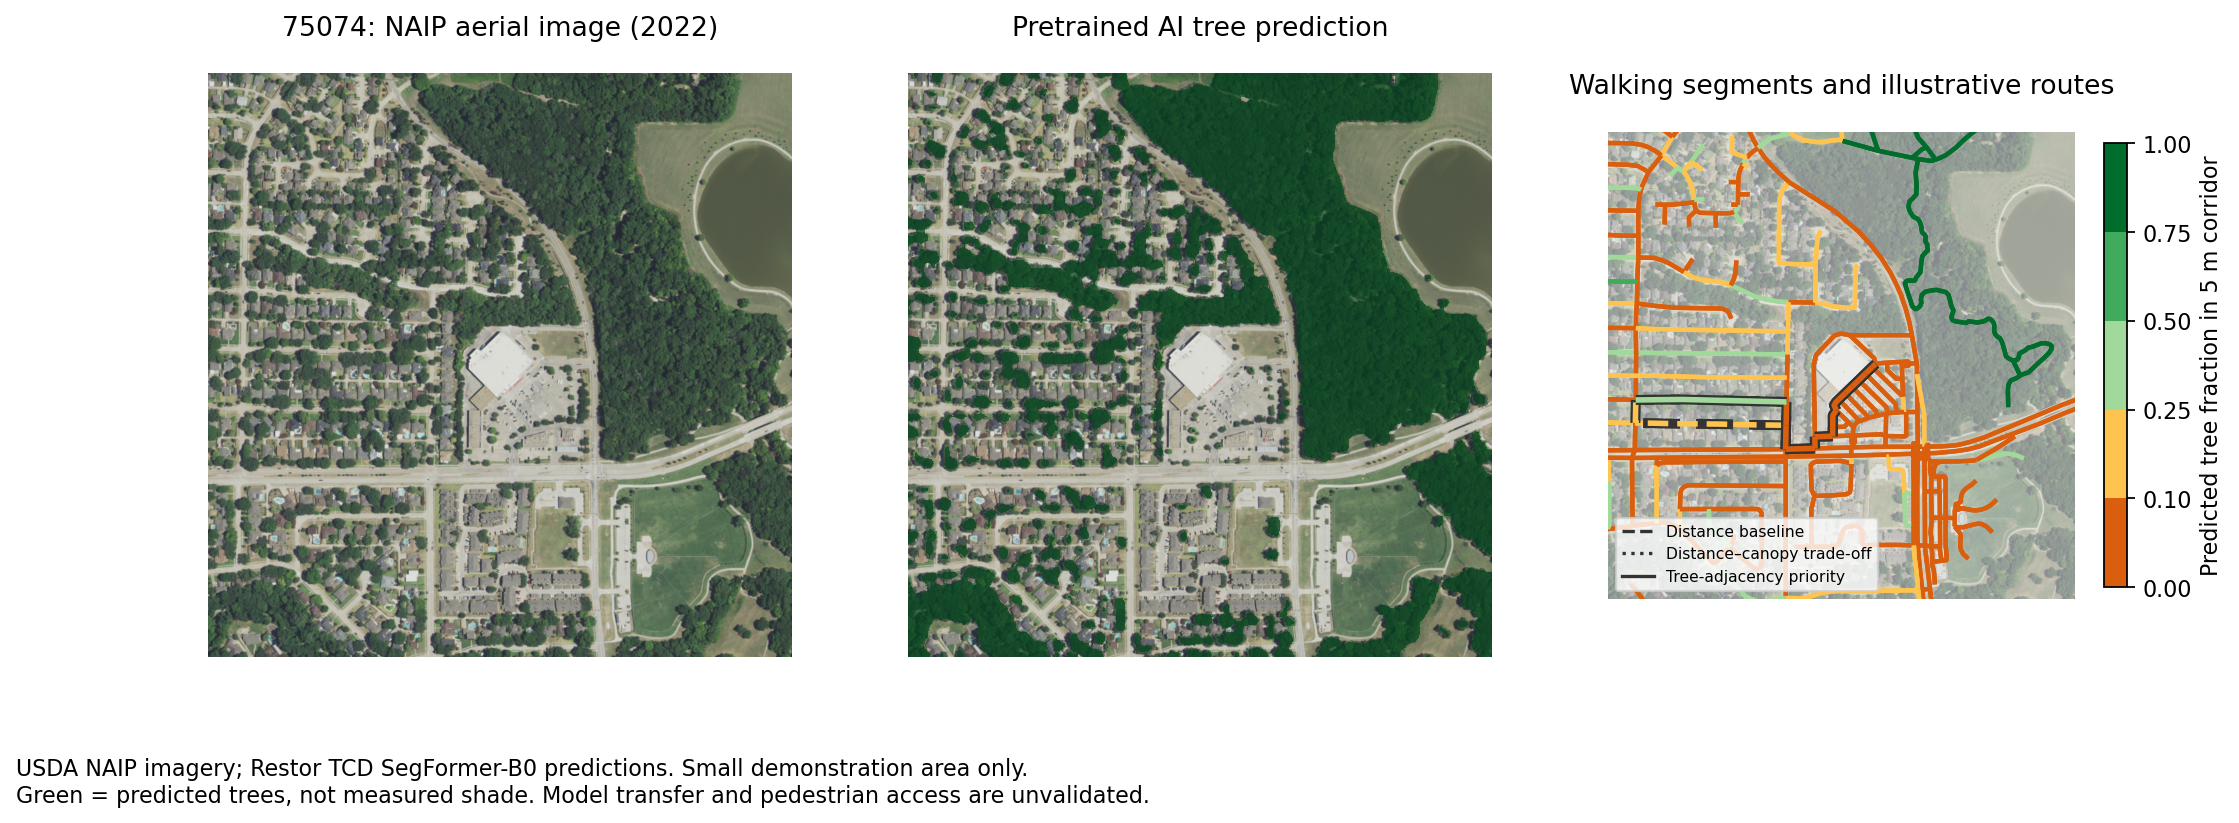

Interactive map: /Users/nalinikantheti/Documents/ChatGPT/EmPath/output/vegetation_geoai/geoai_canopy_routes.html


In [6]:
from visualize_geoai_demo import visualize
summary=visualize()
display(summary)
for r in records:
    display(Markdown('### ZIP '+r['zip']))
    display(Image(filename=str(ROOT/'output/vegetation_geoai'/('geoai_demo_'+r['zip']+'.png')),width=1100))
print('Interactive map:', ROOT/'output/vegetation_geoai/geoai_canopy_routes.html')

## 6. Validate before claiming accuracy

- Review `output/vegetation_geoai/validation_patches/`: 16 fixed imagery-only patches.
- Independently outline tree cover or estimate its fraction, then record observations in a **copy** of `manual_review_template.csv`. Keep the original template and model results separate from annotation until review is finished.
- Compare hand-drawn masks with predicted masks for pixel precision, recall and IoU; aggregate fractions alone cannot measure pixel-level accuracy.
- Check trees, grass/shrubs, building shadows, roads, and model boundary errors. Review more independent locations before expanding coverage.
- Inspect route entrances, sidewalks and crossings separately; accurate tree segmentation cannot validate pedestrian access.
- No local accuracy percentage is reported until independent labels exist.

## 7. What this completes

Actual imagery-based GeoAI inference, georeferenced prediction rasters, predicted vector polygons, edge attributes, route-cost demonstration, and visual-review material. It does not complete whole-ZIP inference, measured shade/heat modeling, sidewalk/building/pavement segmentation, or local accuracy validation.

## References

- Restor/ETH Zurich. [TCD pretrained model and limitations](https://huggingface.co/restor/tcd-segformer-mit-b0).
- Restor. [TCD implementation](https://github.com/Restor-Foundation/tcd).
- USDA. [NAIP imagery](https://naip-usdaonline.hub.arcgis.com/).
- Melnikov et al. (2022). [Behavioural thermal regulation explains pedestrian path choices in hot urban environments](https://doi.org/10.1038/s41598-022-06383-5).


## Explanatory image sequences for the website
These figures separate input imagery, model predictions, and GIS path scoring. They intentionally omit route-comparison overlays. One example is shown for each ZIP; they illustrate the process and are not validation samples.

In [ ]:
from export_geoai_sequences import main as export_sequences
for item in export_sequences():
    display(Image(filename=str(ROOT/'output/vegetation_geoai'/item['image']),width=1100))